In [ ]:
# Retail Data Analysis by: John Ivan Gabriel Gacay
# Sample Data used: https://www.kaggle.com/datasets/mohammadtalib786/retail-sales-dataset?resource=download

In [3]:
# setup the file and prerequisites
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# displays values with a float format rounded to two decimals
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

# for money values
money = mtick.StrMethodFormatter("${x:,.0f}")

In [7]:
# Read and laod the data
df = pd.read_csv("retail_sales_dataset.csv")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 1,000 | Columns: 9


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [9]:
# Display Data quality and types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [11]:
checks = {
    "Missing values": int(df.isna().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Duplicate Transaction IDs": int(df["Transaction ID"].duplicated().sum()),
    "Rows where Total != Qty x Price": int((df["Quantity"] * df["Price per Unit"] != df["Total Amount"]).sum()),
    "Non-positive quantity or price": int(((df["Quantity"] <= 0) | (df["Price per Unit"] <= 0)).sum()),
}
pd.Series(checks, name="count").to_frame()

,count
Missing values,0
Duplicate rows,0
Duplicate Transaction IDs,0
Rows where Total != Qty x Price,0
Non-positive quantity or price,0


In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Transaction ID,"1,000.00",500.50,288.82,1.00,250.75,500.50,750.25,"1,000.00"
Age,"1,000.00",41.39,13.68,18.00,29.00,42.00,53.00,64.00
Quantity,"1,000.00",2.51,1.13,1.00,1.00,3.00,4.00,4.00
Price per Unit,"1,000.00",179.89,189.68,25.00,30.00,50.00,300.00,500.00
Total Amount,"1,000.00",456.00,560.00,25.00,60.00,135.00,900.00,"2,000.00"


In [15]:
# Data Cleaning

df = df.rename(columns={
    "Transaction ID": "transaction_id",
    "Date": "date",
    "Customer ID": "customer_id",
    "Gender": "gender",
    "Age": "age",
    "Product Category": "product_category",
    "Quantity": "quantity",
    "Price per Unit": "price_per_unit",
    "Total Amount": "total_amount",
})

df["date"] = pd.to_datetime(df["date"])

# Time features
df["year_month"] = df["date"].dt.to_period("M").astype(str)
df["month_num"] = df["date"].dt.month
df["month_name"] = df["date"].dt.strftime("%b")
df["day_of_week"] = df["date"].dt.day_name()
df["quarter"] = "Q" + df["date"].dt.quarter.astype(str)

# Customer feature
df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"],
)

# Price tier: the dataset has only 5 price points (25, 30, 50, 300, 500)
df["price_tier"] = np.where(df["price_per_unit"] >= 300, "Premium (300+)", "Budget (<=50)")

df.head()

,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount,year_month,month_num,month_name,day_of_week,quarter,age_group,price_tier
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023-11,11,Nov,Friday,Q4,26-35,Budget (<=50)
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023-02,2,Feb,Monday,Q1,26-35,Premium (300+)
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023-01,1,Jan,Friday,Q1,46-55,Budget (<=50)
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023-05,5,May,Sunday,Q2,36-45,Premium (300+)
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023-05,5,May,Saturday,Q2,26-35,Budget (<=50)


In [17]:
# January 2024 contains a single day of data - flag it so it doesn't distort monthly trends
print(df.groupby("year_month")["date"].agg(["min", "max", "count"]).tail(3))

full_year = df[df["date"] < "2024-01-01"].copy()
print(f"\nRows used for monthly trend analysis: {len(full_year):,} of {len(df):,}")

                  min        max  count
year_month                             
2023-11    2023-11-01 2023-11-30     78
2023-12    2023-12-01 2023-12-31     91
2024-01    2024-01-01 2024-01-01      2

Rows used for monthly trend analysis: 998 of 1,000


In [19]:
# List of Key Performance Indicators
kpis = {
    "Total revenue": f"${df['total_amount'].sum():,.0f}",
    "Transactions": f"{len(df):,}",
    "Unique customers": f"{df['customer_id'].nunique():,}",
    "Units sold": f"{df['quantity'].sum():,}",
    "Average order value": f"${df['total_amount'].mean():,.2f}",
    "Avg units per order": f"{df['quantity'].mean():.2f}",
}
pd.Series(kpis, name="Value").to_frame()

,Value
Total revenue,"$456,000"
Transactions,"1,000"
Unique customers,"1,000"
Units sold,"2,514"
Average order value,$456.00
Avg units per order,2.51


In [21]:
# Show revenue trend

monthly = (
    full_year.groupby("year_month")
    .agg(revenue=("total_amount", "sum"), orders=("transaction_id", "count"))
    .assign(aov=lambda d: d["revenue"] / d["orders"])
)
monthly["mom_growth_pct"] = monthly["revenue"].pct_change() * 100
monthly

,revenue,orders,aov,mom_growth_pct
year_month,,,,
2023-01,35450,76,466.45,NaN
2023-02,44060,85,518.35,24.29
2023-03,28990,73,397.12,-34.20
2023-04,33870,86,393.84,16.83
2023-05,53150,105,506.19,56.92
2023-06,36715,77,476.82,-30.92
2023-07,35465,72,492.57,-3.40
2023-08,36960,94,393.19,4.22
2023-09,23620,65,363.38,-36.09


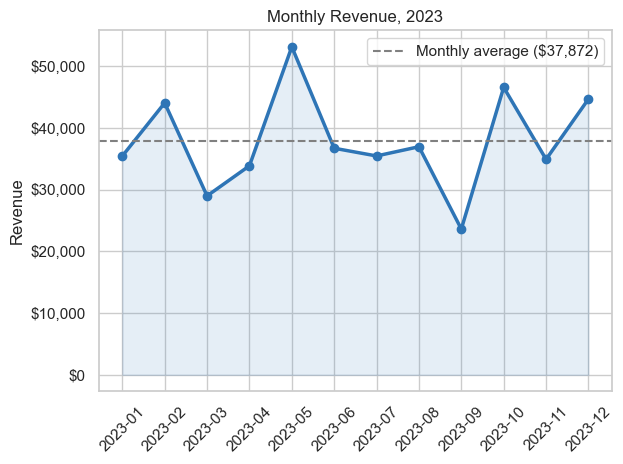

In [23]:
# Display in a line chart; x for months ; y for amount 

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["revenue"], marker="o", linewidth=2.5, color="#2E75B6")
ax.fill_between(monthly.index, monthly["revenue"], alpha=0.12, color="#2E75B6")
ax.axhline(monthly["revenue"].mean(), color="gray", linestyle="--", label=f"Monthly average (${monthly['revenue'].mean():,.0f})")
ax.set_title("Monthly Revenue, 2023")
ax.set_xlabel("")
ax.set_ylabel("Revenue")
ax.yaxis.set_major_formatter(money)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
# best and worst performance 

best, worst = monthly["revenue"].idxmax(), monthly["revenue"].idxmin()
print(f"Best month : {best} (${monthly.loc[best, 'revenue']:,.0f})")
print(f"Worst month: {worst} (${monthly.loc[worst, 'revenue']:,.0f})")

quarterly = full_year.groupby("quarter")["total_amount"].sum()
print("\nRevenue by quarter:")
print(quarterly.map("${:,.0f}".format).to_string())

Best month : 2023-05 ($53,150)
Worst month: 2023-09 ($23,620)

Revenue by quarter:
quarter
Q1    $108,500
Q2    $123,735
Q3     $96,045
Q4    $126,190


In [27]:
# Product Category performance
cat = (
    df.groupby("product_category")
    .agg(
        revenue=("total_amount", "sum"),
        orders=("transaction_id", "count"),
        units=("quantity", "sum"),
        aov=("total_amount", "mean"),
    )
    .assign(revenue_share_pct=lambda d: d["revenue"] / d["revenue"].sum() * 100)
    .sort_values("revenue", ascending=False)
)
cat


,revenue,orders,units,aov,revenue_share_pct
product_category,,,,,
Electronics,156905,342,849,458.79,34.41
Clothing,155580,351,894,443.25,34.12
Beauty,143515,307,771,467.48,31.47


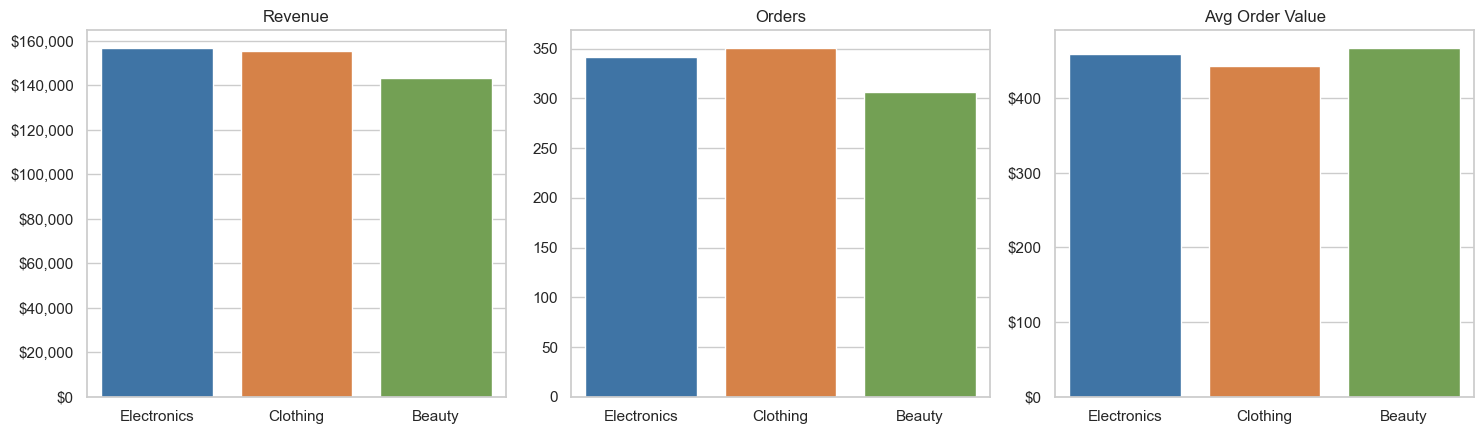

In [29]:
# Displayed in bar charts

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
palette = ["#2E75B6", "#ED7D31", "#70AD47"]

for ax, (col, title, fmt) in zip(
    axes,
    [("revenue", "Revenue", money), ("orders", "Orders", None), ("aov", "Avg Order Value", money)],
):
    sns.barplot(x=cat.index, y=cat[col], hue=cat.index, palette=palette, legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if fmt:
        ax.yaxis.set_major_formatter(fmt)

plt.tight_layout()
plt.show()

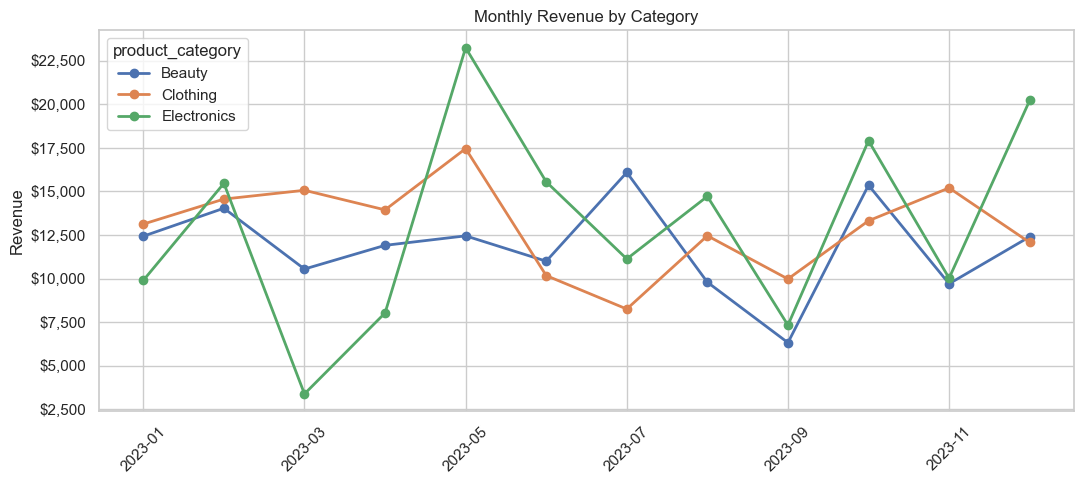

In [31]:
# Comparison in line chart by month

cat_month = full_year.pivot_table(index="year_month", columns="product_category", values="total_amount", aggfunc="sum")

ax = cat_month.plot(marker="o", linewidth=2, figsize=(11, 5))
ax.set_title("Monthly Revenue by Category")
ax.set_xlabel("")
ax.set_ylabel("Revenue")
ax.yaxis.set_major_formatter(money)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
# Price tier analysis
tier = (
    df.groupby("price_tier")
    .agg(
        orders=("transaction_id", "count"),
        units=("quantity", "sum"),
        revenue=("total_amount", "sum"),
    )
    .assign(
        order_share_pct=lambda d: d["orders"] / d["orders"].sum() * 100,
        revenue_share_pct=lambda d: d["revenue"] / d["revenue"].sum() * 100,
    )
)
tier

,orders,units,revenue,order_share_pct,revenue_share_pct
price_tier,,,,,
Budget (<=50),604,1501,53100,60.40,11.64
Premium (300+),396,1013,402900,39.60,88.36


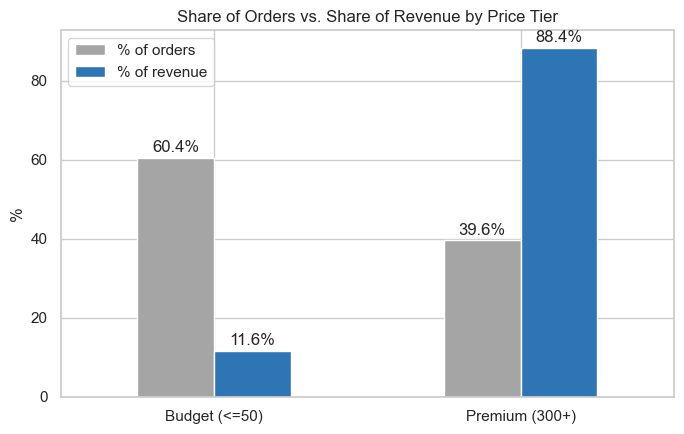

In [35]:
# Comparison
share = tier[["order_share_pct", "revenue_share_pct"]].rename(
    columns={"order_share_pct": "% of orders", "revenue_share_pct": "% of revenue"}
)
ax = share.plot(kind="bar", figsize=(7, 4.5), color=["#A5A5A5", "#2E75B6"], rot=0)
ax.set_title("Share of Orders vs. Share of Revenue by Price Tier")
ax.set_xlabel("")
ax.set_ylabel("%")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2)
plt.tight_layout()
plt.show()

In [37]:
# Customer demographics
gender = df.groupby("gender").agg(
    revenue=("total_amount", "sum"),
    orders=("transaction_id", "count"),
    aov=("total_amount", "mean"),
)
gender

,revenue,orders,aov
gender,,,
Female,232840,510,456.55
Male,223160,490,455.43


In [39]:
# age group
age = (
    df.groupby("age_group", observed=True)
    .agg(revenue=("total_amount", "sum"), orders=("transaction_id", "count"), aov=("total_amount", "mean"))
)
age

,revenue,orders,aov
age_group,,,
18-25,84550,169,500.30
26-35,98480,205,480.39
36-45,91870,202,454.80
46-55,100690,229,439.69
56-65,80410,195,412.36


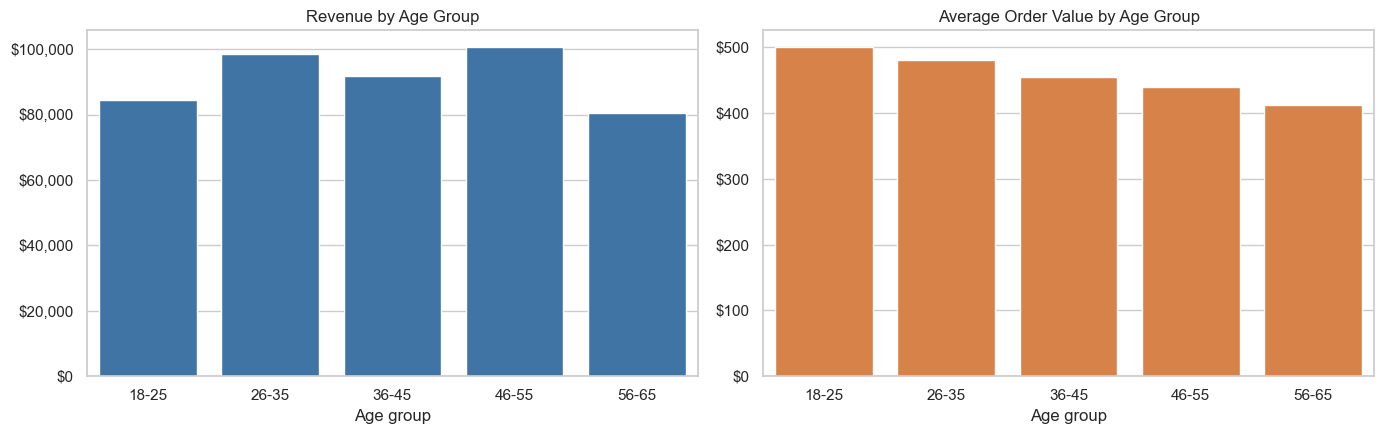

In [43]:
# Revenue by age group

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.barplot(x=age.index, y=age["revenue"], color="#2E75B6", ax=axes[0])
axes[0].set_title("Revenue by Age Group")
axes[0].set_xlabel("Age group")
axes[0].set_ylabel("")
axes[0].yaxis.set_major_formatter(money)

sns.barplot(x=age.index, y=age["aov"], color="#ED7D31", ax=axes[1])
axes[1].set_title("Average Order Value by Age Group")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("")
axes[1].yaxis.set_major_formatter(money)

plt.tight_layout()
plt.show()

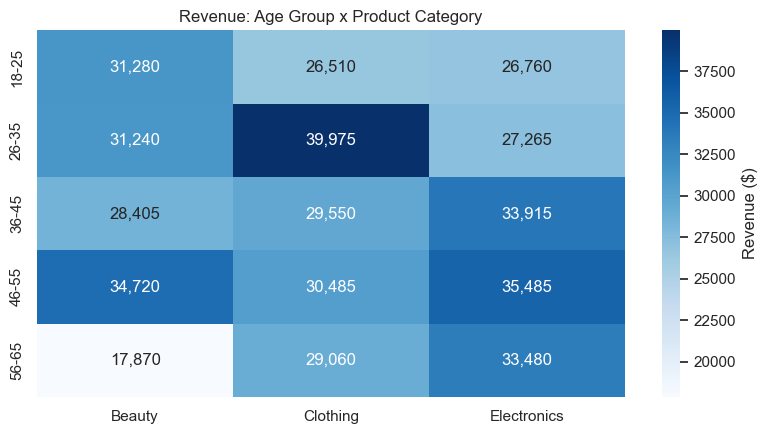

In [45]:
#Revenue of Age Group x Product Category
# A.k.a. What does each age group buy?
heat = df.pivot_table(index="age_group", columns="product_category", values="total_amount", aggfunc="sum", observed=True)

plt.figure(figsize=(8, 4.5))
sns.heatmap(heat, annot=True, fmt=",.0f", cmap="Blues", cbar_kws={"label": "Revenue ($)"})
plt.title("Revenue: Age Group x Product Category")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

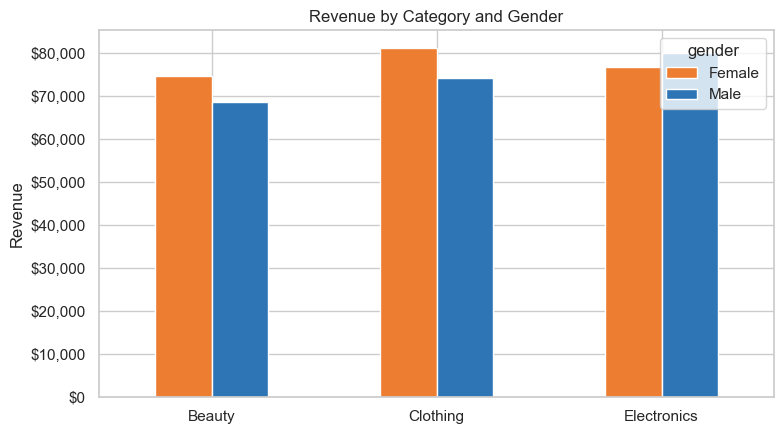

In [47]:
# Gender x category
gc = df.pivot_table(index="product_category", columns="gender", values="total_amount", aggfunc="sum")
ax = gc.plot(kind="bar", figsize=(8, 4.5), color=["#ED7D31", "#2E75B6"], rot=0)
ax.set_title("Revenue by Category and Gender")
ax.set_xlabel("")
ax.set_ylabel("Revenue")
ax.yaxis.set_major_formatter(money)
plt.tight_layout()
plt.show()

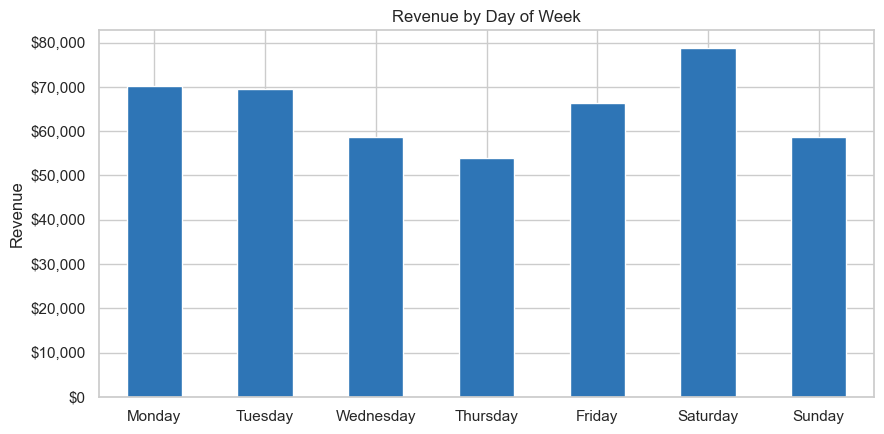

,revenue,orders
day_of_week,,
Monday,70250,146
Tuesday,69440,161
Wednesday,58770,139
Thursday,53835,123
Friday,66290,143
Saturday,78815,150
Sunday,58600,138


In [49]:
# Revenue by day of week

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = df.groupby("day_of_week").agg(revenue=("total_amount", "sum"), orders=("transaction_id", "count")).reindex(order)

ax = dow["revenue"].plot(kind="bar", figsize=(9, 4.5), color="#2E75B6", rot=0)
ax.set_title("Revenue by Day of Week")
ax.set_xlabel("")
ax.set_ylabel("Revenue")
ax.yaxis.set_major_formatter(money)
plt.tight_layout()
plt.show()
dow

Top 10% of orders generate 38.2% of revenue
Top 20% of orders generate 62.5% of revenue


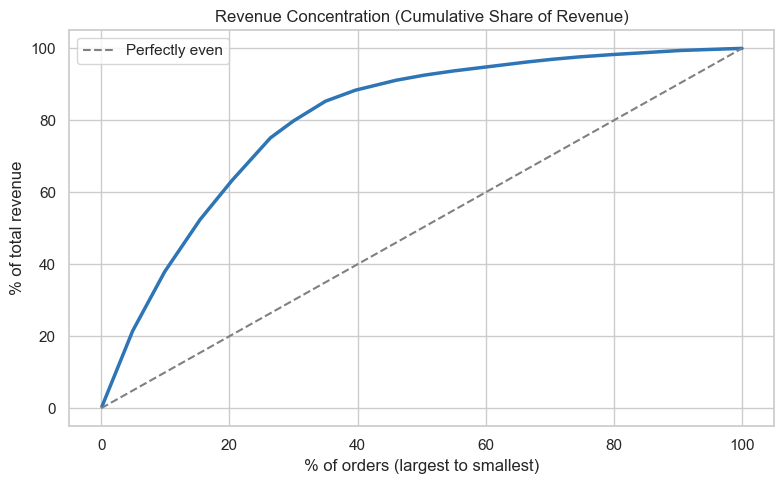

In [51]:
# Cumulative share

sorted_rev = df["total_amount"].sort_values(ascending=False).reset_index(drop=True)
cum_share = sorted_rev.cumsum() / sorted_rev.sum() * 100
pct_orders = (np.arange(1, len(sorted_rev) + 1) / len(sorted_rev)) * 100

top10_share = cum_share.iloc[int(len(df) * 0.10) - 1]
top20_share = cum_share.iloc[int(len(df) * 0.20) - 1]
print(f"Top 10% of orders generate {top10_share:.1f}% of revenue")
print(f"Top 20% of orders generate {top20_share:.1f}% of revenue")

plt.figure(figsize=(8, 5))
plt.plot(pct_orders, cum_share, linewidth=2.5, color="#2E75B6")
plt.plot([0, 100], [0, 100], linestyle="--", color="gray", label="Perfectly even")
plt.title("Revenue Concentration (Cumulative Share of Revenue)")
plt.xlabel("% of orders (largest to smallest)")
plt.ylabel("% of total revenue")
plt.legend()
plt.tight_layout()
plt.show()

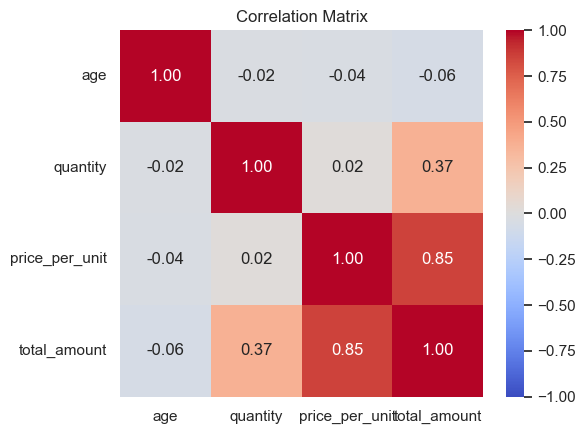

In [53]:
# Correlation matrix of data

corr = df[["age", "quantity", "price_per_unit", "total_amount"]].corr()
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [55]:
# Export cleaned data

export_cols = [
    "transaction_id", "date", "year_month", "quarter", "month_num", "month_name", "day_of_week",
    "customer_id", "gender", "age", "age_group",
    "product_category", "quantity", "price_per_unit", "price_tier", "total_amount",
]
df[export_cols].to_csv("retail_sales_clean.csv", index=False)
print(f"Saved retail_sales_clean.csv ({len(df):,} rows, {len(export_cols)} columns)")

Saved retail_sales_clean.csv (1,000 rows, 16 columns)
